<>:29: SyntaxWarning: invalid escape sequence '\e'
<>:33: SyntaxWarning: invalid escape sequence '\e'
<>:29: SyntaxWarning: invalid escape sequence '\e'
<>:33: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_480007/823253487.py:29: SyntaxWarning: invalid escape sequence '\e'
  plt.text(0.18, 0.18, 'SAFE ZONE\n($\epsilon < 0.5$)\nMedian Logic Valid',
/tmp/ipykernel_480007/823253487.py:33: SyntaxWarning: invalid escape sequence '\e'
  plt.text(0.78, 0.78, 'FAILURE ZONE\n($\epsilon \geq 0.5$)\nMedian Logic Fails',


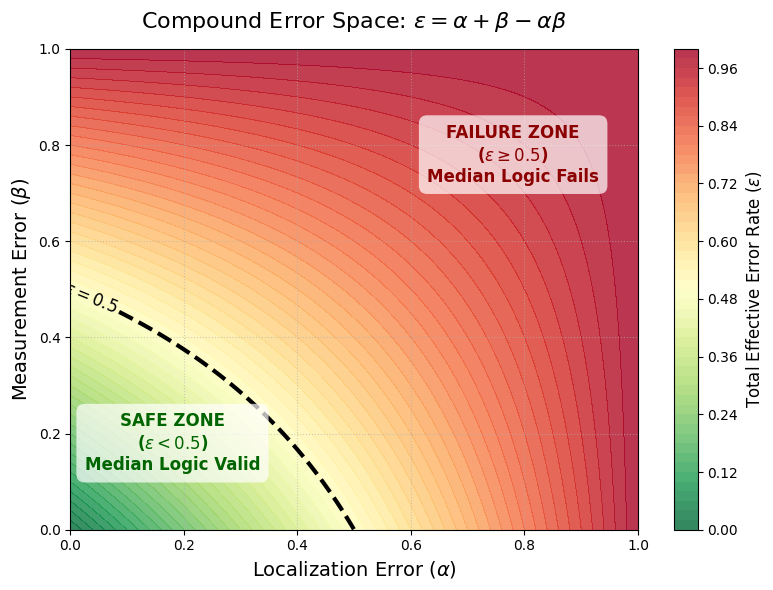

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the grid for alpha and beta
alpha = np.linspace(0, 1, 500)
beta = np.linspace(0, 1, 500)
A, B = np.meshgrid(alpha, beta)

# Calculate compound error epsilon: eps = a + b - a*b
E = A + B - A * B

# Create the plot
plt.figure(figsize=(8, 6))

# Plot the background color mesh for the error gradient
contour = plt.contourf(A, B, E, levels=50, cmap='RdYlGn_r', alpha=0.8)

# Add a distinct line for the 0.5 threshold
threshold_line = plt.contour(A, B, E, levels=[0.5], colors='black', linewidths=3, linestyles='dashed')

# Add labels to the threshold line
plt.clabel(threshold_line, inline=True, fmt=r'$\epsilon = 0.5$', fontsize=12, rightside_up=True)

# Add colorbar
cbar = plt.colorbar(contour)
cbar.set_label(r'Total Effective Error Rate ($\epsilon$)', fontsize=12)

# Add text annotations for the zones
plt.text(0.18, 0.18, 'SAFE ZONE\n($\epsilon < 0.5$)\nMedian Logic Valid', 
         fontsize=12, color='darkgreen', ha='center', va='center', fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.5'))

plt.text(0.78, 0.78, 'FAILURE ZONE\n($\epsilon \geq 0.5$)\nMedian Logic Fails', 
         fontsize=12, color='darkred', ha='center', va='center', fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.5'))

# Axis labels and title
plt.xlabel(r'Localization Error ($\alpha$)', fontsize=14)
plt.ylabel(r'Measurement Error ($\beta$)', fontsize=14)
plt.title(r'Compound Error Space: $\epsilon = \alpha + \beta - \alpha\beta$', fontsize=16, pad=15)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, linestyle=':', alpha=0.6)

# Save the plot
plt.tight_layout()
# plt.savefig('compound_error_plot.png', dpi=300)

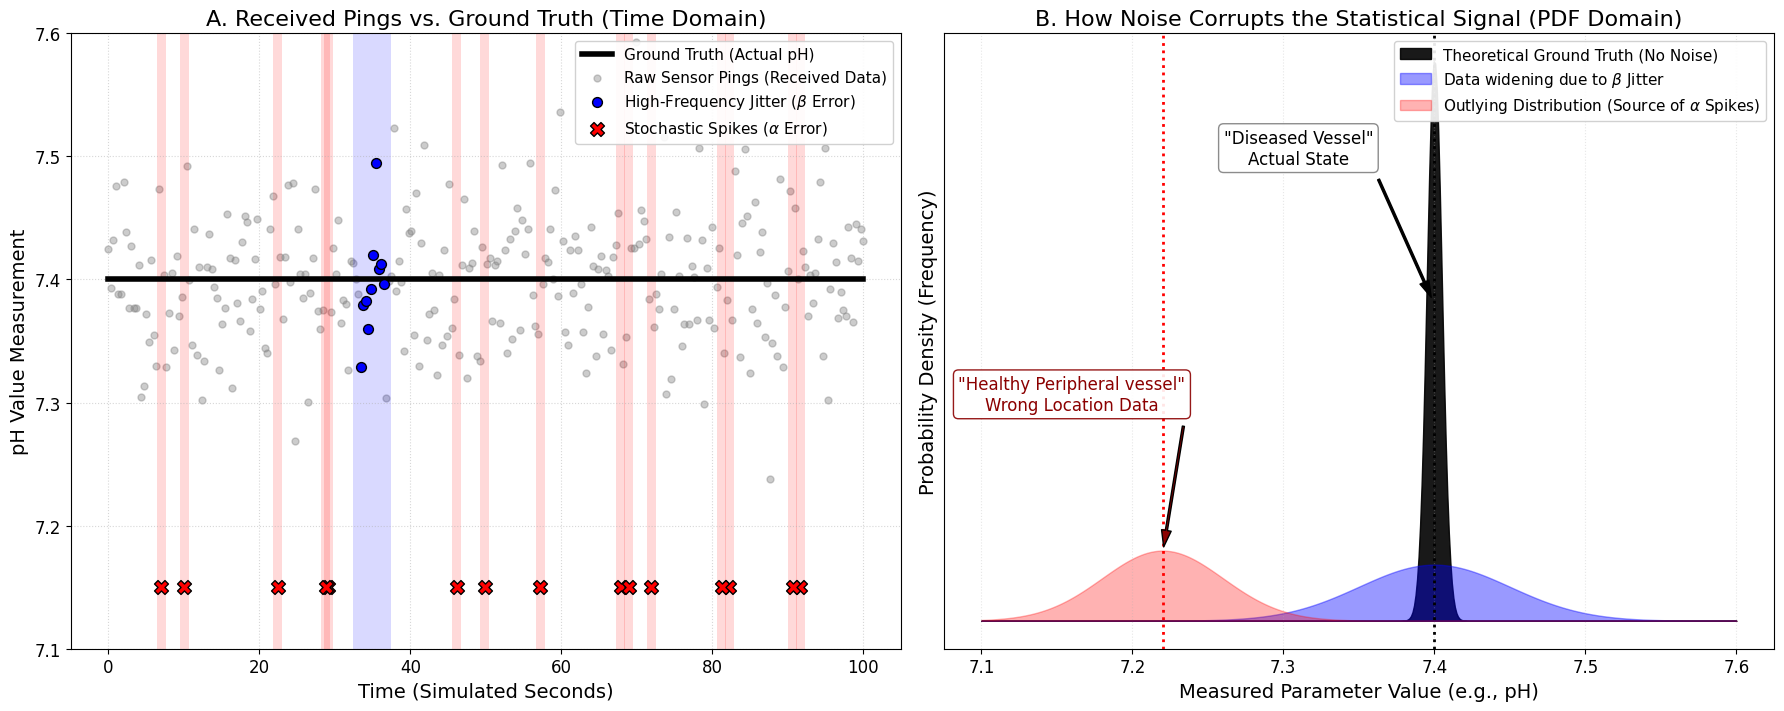

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Set global seed for reproducibility
np.random.seed(42)

# ==========================================
# A. CREATE SUBPLOTS (1 Row, 2 Columns)
# ==========================================
# Increase size significantly for side-by-side view
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
plt.rcParams.update({'font.size': 12}) # Increase general font size

# Add a Global Main Title
# fig.suptitle('Visualizing Noisy Raw Sensor Data: Time and Statistical Domains', fontsize=22, fontweight='bold', y=1.02)

# ==============================================================================
# SUBPLOT 1 (LEFT): Time-Series Visualization
# ==============================================================================
# 1. Generate stable physiological ground truth data (baseline pH 7.4)
time_raw = np.linspace(0, 100, 300)
ground_truth_stable = np.full_like(time_raw, 7.4)

# 2. Simulate Measurement Jitter (Beta Error)
beta_variance = 0.05
measurement_noise = np.random.normal(0, beta_variance, len(time_raw))
raw_pings_beta = ground_truth_stable + measurement_noise

# 3. Simulate Localization Spikes (Alpha Error)
num_outliers = 15
alpha_indices = np.random.choice(len(time_raw), num_outliers, replace=False)
alpha_outlier_value = 7.15 
raw_pings_combined = raw_pings_beta.copy()
raw_pings_combined[alpha_indices] = alpha_outlier_value

# 4. Plotting on ax1
# Clean ground truth line
ax1.plot(time_raw, ground_truth_stable, color='black', linewidth=4, label='Ground Truth (Actual pH)')

# All noisy raw pings (gray dots)
ax1.scatter(time_raw, raw_pings_combined, color='gray', alpha=0.4, s=25, label='Raw Sensor Pings (Received Data)')

# --- Highlight Beta (Jitter) ---
jitter_slice = slice(100, 110)
# Add Blue Shaded Region
ax1.axvspan(time_raw[100]-1, time_raw[109]+1, color='blue', alpha=0.15, lw=0)
# Highlight the specific dots
ax1.scatter(time_raw[jitter_slice], raw_pings_combined[jitter_slice], color='blue', s=50, edgecolor='black', zorder=5, label=r'High-Frequency Jitter ($\beta$ Error)')

# --- Highlight Alpha (Spikes) ---
# Add Red Shaded Regions around ALL outliers
for idx in alpha_indices:
    ax1.axvspan(time_raw[idx]-0.6, time_raw[idx]+0.6, color='red', alpha=0.15, lw=0)
# Plot all outlier dots as Red 'X'
ax1.scatter(time_raw[alpha_indices], raw_pings_combined[alpha_indices], color='red', marker='X', s=100, edgecolor='black', zorder=10, label=r'Stochastic Spikes ($\alpha$ Error)')

# Subplot Formatting
ax1.set_title('A. Received Pings vs. Ground Truth (Time Domain)', fontsize=16)
ax1.set_xlabel('Time (Simulated Seconds)', fontsize=14)
ax1.set_ylabel('pH Value Measurement', fontsize=14)
ax1.set_ylim(7.1, 7.6)
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend(loc='upper right', fontsize=11, frameon=True, facecolor='white', framealpha=0.9)


# ==============================================================================
# SUBPLOT 2 (RIGHT): Statistical Distribution Visualization
# ==============================================================================
# 1. Generate mathematical ideal distributions
x_axis = np.linspace(7.1, 7.6, 500)
target_pH = 7.4
adjacent_zone_pH = 7.22

# Flawless Signal (Theoretical Ground Truth)
dist_flawless = norm.pdf(x_axis, target_pH, 0.005)
# Signal corrupted by Beta (Jitter widens the distribution)
dist_beta_corrupted = norm.pdf(x_axis, target_pH, 0.05)
# Outlying Distribution (Source of Alpha Noise)
dist_alpha_source = norm.pdf(x_axis, adjacent_zone_pH, 0.04)

# 2. Fill and plot the distributions on ax2
ax2.fill_between(x_axis, dist_flawless, color='black', alpha=0.9, label='Theoretical Ground Truth (No Noise)')
ax2.fill_between(x_axis, dist_beta_corrupted, color='blue', alpha=0.4, label=r'Data widening due to $\beta$ Jitter')
ax2.fill_between(x_axis, dist_alpha_source, color='red', alpha=0.3, label=r'Outlying Distribution (Source of $\alpha$ Spikes)')

# Vertical lines for clean means
ax2.axvline(target_pH, color='black', linestyle=':', linewidth=2)
ax2.axvline(adjacent_zone_pH, color='red', linestyle=':', linewidth=2)

# Subplot Formatting
ax2.set_title('B. How Noise Corrupts the Statistical Signal (PDF Domain)', fontsize=16)
ax2.set_xlabel('Measured Parameter Value (e.g., pH)', fontsize=14)
ax2.set_ylabel('Probability Density (Frequency)', fontsize=14)
ax2.set_yticks([]) # Hide Y-axis frequency numbers for clarity
ax2.grid(True, linestyle=':', alpha=0.3)

# 3. Clean Annotations with Arrows (Fixes the Overlap Issue)
# Annotation for the Black Peak
ax2.annotate('"Diseased Vessel"\nActual State', 
             xy=(target_pH, 45), xytext=(target_pH - 0.09, 65),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=7),
             fontsize=12, ha='center', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))

# Annotation for the Red Peak
ax2.annotate('"Healthy Peripheral vessel"\nWrong Location Data', 
             xy=(adjacent_zone_pH, 9.5), xytext=(adjacent_zone_pH - 0.06, 30),
             arrowprops=dict(facecolor='darkred', shrink=0.05, width=1.5, headwidth=7),
             fontsize=12, color='darkred', ha='center', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="darkred", alpha=0.9))

ax2.legend(loc='upper right', fontsize=11, frameon=True, facecolor='white', framealpha=0.9)

# ==========================================
# C. CONNECTION TEXT & SAVE
# ==========================================
# connection_text = r'$\beta$ Jitter (Plot A: Blue jitter) transforms the flawless signal (Plot B: Black spike) into a fuzzy cloud (Plot B: Blue wide curve). ' \
#                   r'$\alpha$ Spikes (Plot A: Red X) represent single points drawn entirely from the outlying distribution (Plot B: Red curve).'
# fig.text(0.5, 0.01, connection_text, ha='center', fontsize=13, style='italic', color='black', 
#          bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray', boxstyle='round,pad=0.6'))

# Adjust layout to fit everything including suptitle and bottom text
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
# plt.savefig('noisy_raw_sensor_combined.png', dpi=300)